# 06 — Evaluation
Mean±SD over folds, pooled out-of-fold analysis (patient-cluster bootstrap CI, McNemar), ROC-AUC, confusion matrices, params/FLOPs/latency. Reads whatever folds are finished — re-run after the CV completes.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score, roc_curve
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path("/mnt/g/Research paper/Research paper/Pneumonia-MultiModel-XAI")
SPLITS_DIR = PROJECT_ROOT / "splits"
RES = PROJECT_ROOT / "results"
SRC_DIR = PROJECT_ROOT / "src"
FIG_DIR = RES / "figures"; FIG_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(SRC_DIR))

CLASSES = ["NORMAL", "BACTERIA", "VIRUS"]
SEED_POOL = 42       # seed used for pooled out-of-fold analysis
N_BOOT = 2000
LAT_RUNS = 100
CPU_THREADS = 4

NAMES = {
    "baseline:efficientnet_v2_s": "EffNetV2-S",
    "proposed:efficientnet_v2_s:eca": "EffNetV2-S + ECA",
    "proposed:efficientnet_v2_s:cbam": "EffNetV2-S + CBAM",
    "baseline:efficientnet_b2": "EffNet-B2",
    "baseline:resnet50": "ResNet-50",
    "baseline:convnext_tiny": "ConvNeXt-T",
    "baseline:swin_t": "Swin-T",
}
BASE = "baseline:efficientnet_v2_s"

In [2]:
# ============================================================
# 1. Collect finished runs
# ============================================================
TAG2SPEC = {s.replace(":", "_"): s for s in NAMES}
rows = []
for d in sorted(RES.glob("fold*_seed*")):
    k, s = d.name.replace("fold", "").split("_seed")
    for rd in sorted(p for p in d.iterdir() if p.is_dir()):
        need = ["summary.json", "test_metrics.json", "test_probs.npz"]
        if rd.name in TAG2SPEC and all((rd / f).exists() for f in need):
            sm = json.loads((rd / "summary.json").read_text())
            tm = json.loads((rd / "test_metrics.json").read_text())
            rows.append({"spec": TAG2SPEC[rd.name], "model": NAMES[TAG2SPEC[rd.name]], "fold": int(k), "seed": int(s),
                         "params_M": sm["params"] / 1e6, "val_acc": sm["best_val_acc"],
                         "best_epoch": sm["best_epoch"], **tm})
runs = pd.DataFrame(rows)
present = [s for s in NAMES if s in set(runs["spec"])]
print(runs.groupby("model").agg(n_runs=("fold", "size"), folds=("fold", lambda x: sorted(set(x)))).loc[[NAMES[s] for s in present]])

                  n_runs folds
model                         
EffNetV2-S             1   [0]
EffNetV2-S + ECA       1   [0]
EffNet-B2              1   [0]
ResNet-50              1   [0]
ConvNeXt-T             1   [0]
Swin-T                 1   [0]


In [3]:
# ============================================================
# 2. Table: mean ± SD over folds (and seeds)
# ============================================================
def ms(x, pct):
    f = 100 if pct else 1
    return f"{f*x.mean():.2f} ± {f*x.std():.2f}" if pct else f"{x.mean():.3f} ± {x.std():.3f}"

tab = []
for s in present:
    r = runs[runs["spec"] == s]
    row = {"Model": NAMES[s], "Runs": len(r),
           "Acc (%)": ms(r["test_acc"], True), "Bal. Acc (%)": ms(r["test_bal_acc"], True),
           "Macro-F1 (%)": ms(r["test_macro_f1"], True), "MCC": ms(r["test_mcc"], False),
           "Kappa": ms(r["test_kappa"], False)}
    for c in CLASSES:
        row[f"{c} F1"] = f"{r[c + '_F1'].mean():.3f}"
    tab.append(row)
tab = pd.DataFrame(tab)
tab.to_csv(RES / "table_mean_sd.csv", index=False)
tab

,Model,Runs,Acc (%),Bal. Acc (%),Macro-F1 (%),MCC,Kappa,NORMAL F1,BACTERIA F1,VIRUS F1
0,EffNetV2-S,1,84.80 ± nan,83.52 ± nan,83.96 ± nan,0.760 ± nan,0.759 ± nan,0.962,0.858,0.699
1,EffNetV2-S + ECA,1,84.88 ± nan,83.72 ± nan,83.90 ± nan,0.762 ± nan,0.761 ± nan,0.948,0.860,0.709
2,EffNet-B2,1,82.66 ± nan,82.16 ± nan,81.96 ± nan,0.728 ± nan,0.728 ± nan,0.950,0.836,0.672
3,ResNet-50,1,81.90 ± nan,81.58 ± nan,81.59 ± nan,0.716 ± nan,0.716 ± nan,0.949,0.826,0.673
4,ConvNeXt-T,1,82.58 ± nan,82.00 ± nan,82.18 ± nan,0.726 ± nan,0.726 ± nan,0.958,0.835,0.672
5,Swin-T,1,82.92 ± nan,81.83 ± nan,81.89 ± nan,0.731 ± nan,0.730 ± nan,0.950,0.842,0.664


In [4]:
# ============================================================
# 3. Pooled out-of-fold predictions (folds finished for ALL models)
# ============================================================
def load_oof(spec, folds, seed):
    ys, ps, pat = [], [], []
    for k in folds:
        d = RES / f"fold{k}_seed{seed}" / spec.replace(":", "_")
        z = np.load(d / "test_probs.npz")
        te = pd.read_csv(SPLITS_DIR / f"fold{k}_test.csv")
        y_csv = te["label"].map({c: i for i, c in enumerate(CLASSES)}).values
        assert len(te) == len(z["y"]) and (y_csv == z["y"]).all(), f"alignment problem: fold{k} {spec}"
        ys.append(z["y"]); ps.append(z["p"]); pat += list(te["patient_id"])
    return np.concatenate(ys), np.concatenate(ps), np.array(pat)

sets = [set(runs[(runs["spec"] == s) & (runs["seed"] == SEED_POOL)]["fold"]) for s in present]
folds_common = sorted(set.intersection(*sets))
print("Folds used for pooled analysis:", folds_common)
OOF = {s: load_oof(s, folds_common, SEED_POOL) for s in present}
y0, _, pat0 = OOF[present[0]]
for s in present:
    assert (OOF[s][0] == y0).all() and (OOF[s][2] == pat0).all()
pid, uniq = pd.factorize(pat0)
P = len(uniq)
print(f"Pooled test images: {len(y0)} | patients: {P}")

Folds used for pooled analysis: [0]
Pooled test images: 1171 | patients: 753


In [5]:
# ============================================================
# 4. Patient-cluster bootstrap CI (pooled OOF)
# ============================================================
def patient_conf(pred):
    C = np.zeros((P, 3, 3), dtype=np.float32)
    np.add.at(C, (pid, y0, pred), 1)
    return C

def acc_f1(C):
    tp = np.einsum("...ii->...i", C)
    rec = tp / np.clip(C.sum(-1), 1, None)
    prec = tp / np.clip(C.sum(-2), 1, None)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return tp.sum(-1) / C.sum((-1, -2)), f1.mean(-1)

rng = np.random.default_rng(42)
W = rng.multinomial(P, np.ones(P) / P, size=N_BOOT).astype(np.float32)   # shared resamples -> paired comparisons

CP, CONF_FULL, BOOT = {}, {}, {}
for s in present:
    pred = OOF[s][1].argmax(1)
    CP[s] = patient_conf(pred)
    CONF_FULL[s] = CP[s].sum(0)
    BOOT[s] = acc_f1(np.einsum("bp,pij->bij", W, CP[s]))

rows = []
for s in present:
    a, f = acc_f1(CONF_FULL[s])
    ba, bf = BOOT[s]
    rows.append({"Model": NAMES[s], "Acc (%)": f"{100*a:.2f}", "Acc 95% CI": f"[{100*np.percentile(ba,2.5):.2f}, {100*np.percentile(ba,97.5):.2f}]",
                 "Macro-F1 (%)": f"{100*f:.2f}", "F1 95% CI": f"[{100*np.percentile(bf,2.5):.2f}, {100*np.percentile(bf,97.5):.2f}]"})
pooled = pd.DataFrame(rows)
pooled.to_csv(RES / "table_pooled_ci.csv", index=False)
pooled

,Model,Acc (%),Acc 95% CI,Macro-F1 (%),F1 95% CI
0,EffNetV2-S,84.80,"[82.00, 87.33]",83.96,"[81.34, 86.27]"
1,EffNetV2-S + ECA,84.88,"[82.13, 87.35]",83.90,"[81.30, 86.23]"
2,EffNet-B2,82.66,"[79.59, 85.45]",81.96,"[79.32, 84.42]"
3,ResNet-50,81.90,"[78.66, 84.83]",81.59,"[78.71, 84.38]"
4,ConvNeXt-T,82.58,"[79.43, 85.43]",82.18,"[79.30, 84.81]"
5,Swin-T,82.92,"[79.71, 85.85]",81.89,"[78.84, 84.63]"


In [6]:
# ============================================================
# 5. Paired tests vs EffNetV2-S baseline (+ baseline vs the other backbones)
#    primary: paired patient-cluster bootstrap ; secondary: exact McNemar (ignores patient clustering)
# ============================================================
Np = np.bincount(pid, minlength=P).astype(np.float32)
CC = {s: np.bincount(pid, weights=(OOF[s][1].argmax(1) == y0).astype(float), minlength=P).astype(np.float32) for s in present}
ACC_B = {s: (W @ CC[s]) / (W @ Np) for s in present}

pairs = [("proposed:efficientnet_v2_s:eca", BASE), ("proposed:efficientnet_v2_s:cbam", BASE),
         (BASE, "baseline:efficientnet_b2"), (BASE, "baseline:resnet50"),
         (BASE, "baseline:convnext_tiny"), (BASE, "baseline:swin_t")]
rows = []
for a, b in pairs:
    if a not in present or b not in present:
        continue
    ca, cb = OOF[a][1].argmax(1) == y0, OOF[b][1].argmax(1) == y0
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())          # A right/B wrong , A wrong/B right
    p_mc = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    d = ACC_B[a] - ACC_B[b]
    p_bs = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
    rows.append({"A vs B": f"{NAMES[a]} vs {NAMES[b]}", "ΔAcc (pp)": f"{100*(ca.mean()-cb.mean()):+.2f}",
                 "95% CI (pp)": f"[{100*np.percentile(d,2.5):+.2f}, {100*np.percentile(d,97.5):+.2f}]",
                 "p (bootstrap)": f"{p_bs:.4f}", "A-only right": n01, "B-only right": n10, "p (McNemar)": f"{p_mc:.4f}"})
sig = pd.DataFrame(rows)
sig.to_csv(RES / "table_significance.csv", index=False)
sig

,A vs B,ΔAcc (pp),95% CI (pp),p (bootstrap),A-only right,B-only right,p (McNemar)
0,EffNetV2-S + ECA vs EffNetV2-S,+0.09,"[-1.49, +1.74]",0.9520,45,44,1.0000
1,EffNetV2-S vs EffNet-B2,+2.13,"[+0.08, +4.11]",0.0480,74,49,0.0300
2,EffNetV2-S vs ResNet-50,+2.90,"[+0.66, +5.14]",0.0120,83,49,0.0039
3,EffNetV2-S vs ConvNeXt-T,+2.22,"[+0.08, +4.37]",0.0480,72,46,0.0210
4,EffNetV2-S vs Swin-T,+1.88,"[-0.25, +4.01]",0.0820,74,52,0.0609


In [7]:
# ============================================================
# 6. ROC-AUC (pooled OOF) + per-class P/R/F1
# ============================================================
auc_rows, prf_rows = [], []
for s in present:
    y, p = OOF[s][0], OOF[s][1]
    r = {"Model": NAMES[s], "AUC macro": round(roc_auc_score(y, p, multi_class="ovr", average="macro"), 4)}
    for i, c in enumerate(CLASSES):
        r[f"AUC {c}"] = round(roc_auc_score((y == i).astype(int), p[:, i]), 4)
    auc_rows.append(r)
    C = CONF_FULL[s]
    for i, c in enumerate(CLASSES):
        pr, rc = C[i, i] / max(C[:, i].sum(), 1), C[i, i] / max(C[i].sum(), 1)
        prf_rows.append({"Model": NAMES[s], "Class": c, "Precision": round(pr, 3), "Recall": round(rc, 3),
                         "F1": round(2 * pr * rc / max(pr + rc, 1e-12), 3)})
auc_tab, prf_tab = pd.DataFrame(auc_rows), pd.DataFrame(prf_rows)
auc_tab.to_csv(RES / "table_auc.csv", index=False); prf_tab.to_csv(RES / "table_per_class_prf.csv", index=False)
display(auc_tab)

,Model,AUC macro,AUC NORMAL,AUC BACTERIA,AUC VIRUS
0,EffNetV2-S,0.9259,0.9846,0.9122,0.8809
1,EffNetV2-S + ECA,0.9378,0.9974,0.9249,0.8911
2,EffNet-B2,0.9325,0.9926,0.9192,0.8856
3,ResNet-50,0.9328,0.9966,0.9200,0.8817
4,ConvNeXt-T,0.9393,0.9958,0.9294,0.8928
5,Swin-T,0.9314,0.9950,0.9183,0.8809


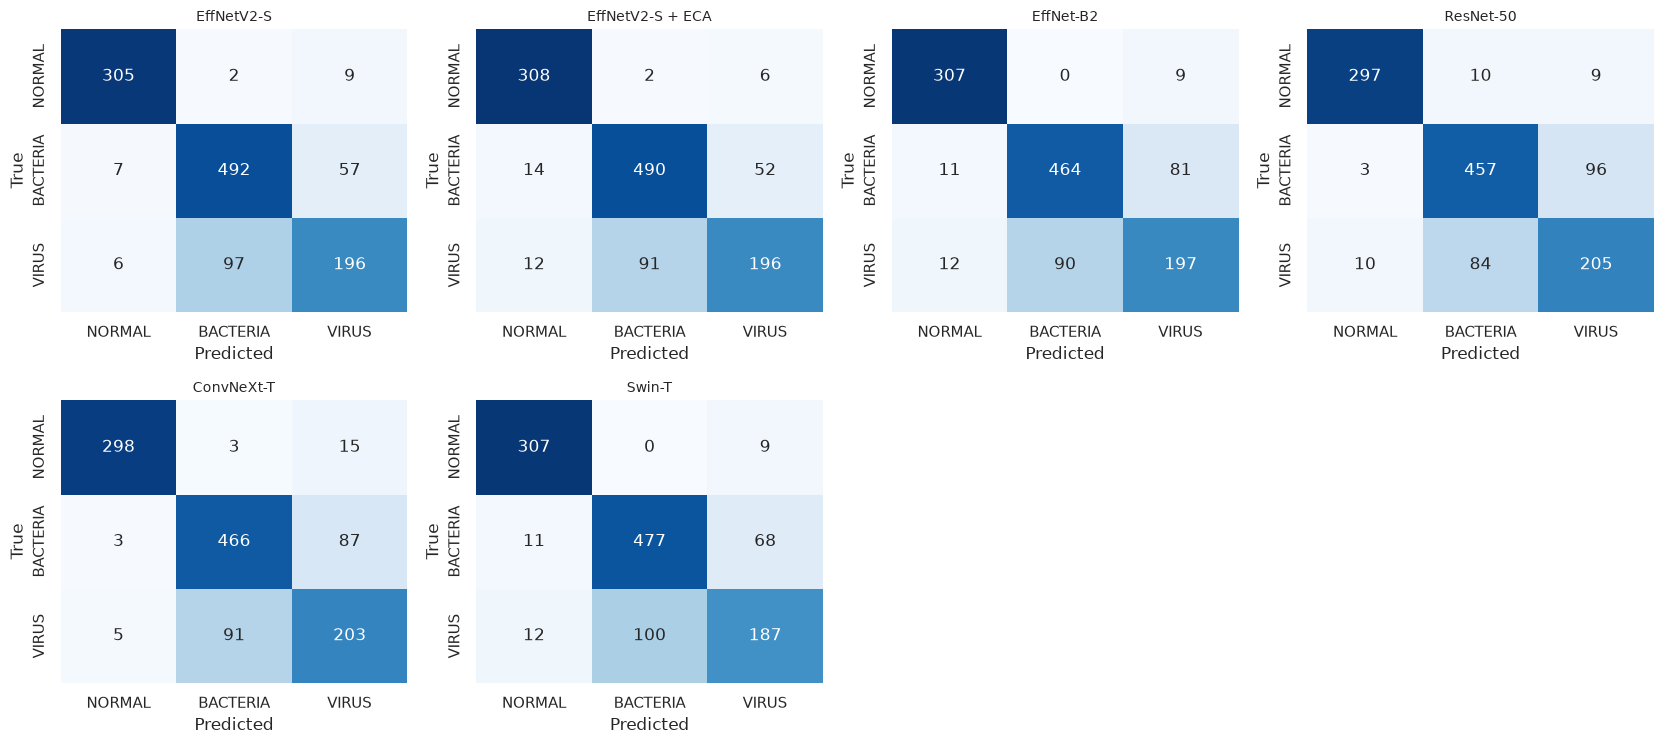

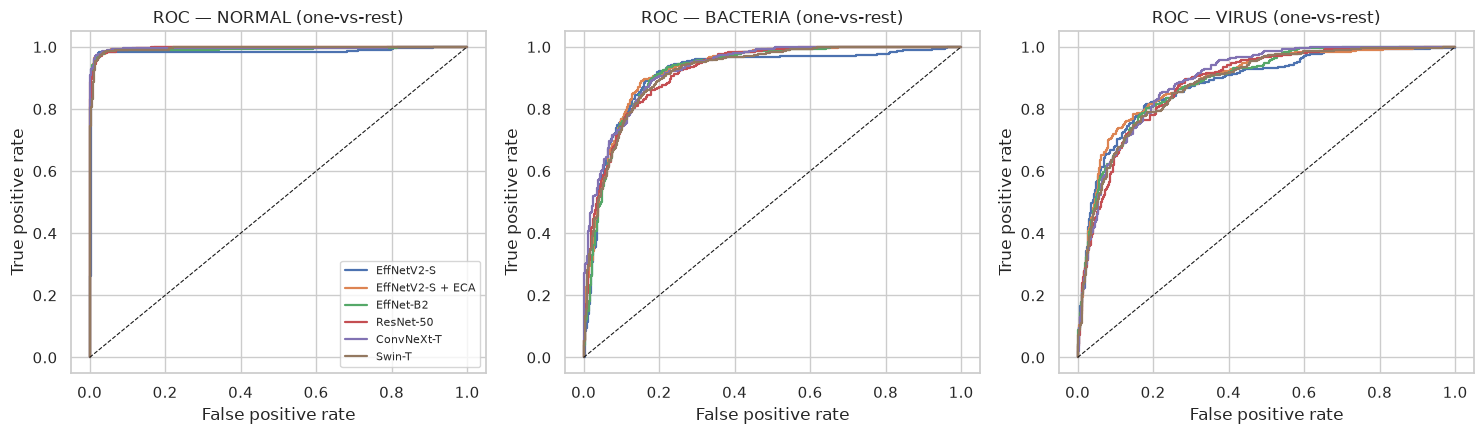

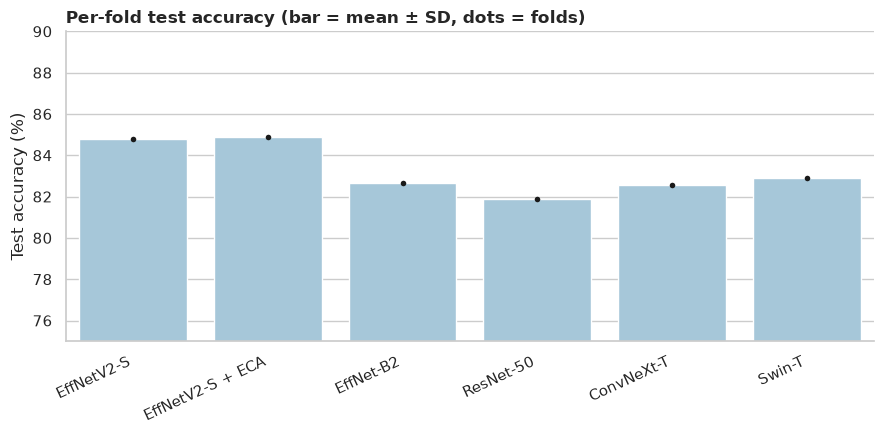

In [8]:
# ============================================================
# 7. Figures (300 dpi): confusion matrices, ROC, per-fold accuracy
# ============================================================
n = len(present); ncol = min(4, n); nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.8 * nrow), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, s in zip(axes.ravel(), present):
    ax.axis("on")
    C = CONF_FULL[s]
    sns.heatmap(C / C.sum(1, keepdims=True), annot=C.astype(int), fmt="d", cmap="Blues", vmin=0, vmax=1,
                cbar=False, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(NAMES[s], fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(FIG_DIR / "confusion_matrices.png", dpi=300, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for i, c in enumerate(CLASSES):
    for s in present:
        fpr, tpr, _ = roc_curve((OOF[s][0] == i).astype(int), OOF[s][1][:, i])
        axes[i].plot(fpr, tpr, label=NAMES[s], lw=1.6)
    axes[i].plot([0, 1], [0, 1], "k--", lw=0.8); axes[i].set_title(f"ROC — {c} (one-vs-rest)")
    axes[i].set_xlabel("False positive rate"); axes[i].set_ylabel("True positive rate")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "roc_curves.png", dpi=300, bbox_inches="tight"); plt.show()

plot_df = runs.assign(acc=100 * runs["test_acc"])
order = [NAMES[s] for s in present]
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="model", y="acc", order=order, errorbar="sd", color="#9ecae1", ax=ax)
sns.stripplot(data=plot_df, x="model", y="acc", order=order, color="k", size=4, ax=ax)
ax.set_ylim(75, 90); ax.set_xlabel(""); ax.set_ylabel("Test accuracy (%)"); plt.xticks(rotation=25, ha="right")
ax.set_title("Per-fold test accuracy (bar = mean ± SD, dots = folds)", loc="left", fontweight="bold")
sns.despine(); plt.tight_layout(); plt.savefig(FIG_DIR / "accuracy_per_fold.png", dpi=300, bbox_inches="tight"); plt.show()

In [9]:
# ============================================================
# 8. Efficiency: params, FLOPs (2xMACs), latency (batch 1, 384px) — close other GPU jobs first
# ============================================================
import time
from torch.utils.flop_counter import FlopCounterMode
from pneumo_models import build_model

@torch.no_grad()
def latency_ms(model, device, runs=LAT_RUNS, warm=20):
    x = torch.randn(1, 3, 384, 384, device=device)
    for _ in range(warm): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(runs): model(x)
    if device.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t) / runs

torch.set_num_threads(CPU_THREADS)
eff = []
for s in present:
    m = build_model(s, pretrained=False).eval()
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        m(torch.randn(1, 3, 384, 384))
    row = {"Model": NAMES[s], "Params (M)": round(sum(p.numel() for p in m.parameters()) / 1e6, 2),
           "GFLOPs": round(fc.get_total_flops() / 1e9, 2),
           "CPU ms": round(latency_ms(m, torch.device("cpu")), 1)}
    if torch.cuda.is_available():
        row["GPU ms"] = round(latency_ms(m.to("cuda"), torch.device("cuda")), 1)
    eff.append(row); del m
    if torch.cuda.is_available(): torch.cuda.empty_cache()
eff = pd.DataFrame(eff)
eff.to_csv(RES / "table_efficiency.csv", index=False)
eff

,Model,Params (M),GFLOPs,CPU ms,GPU ms
0,EffNetV2-S,20.18,16.73,106.4,17.6
1,EffNetV2-S + ECA,20.18,16.73,96.0,19.7
2,EffNet-B2,7.71,3.86,67.7,15.4
3,ResNet-50,23.51,24.02,141.0,8.7
4,ConvNeXt-T,27.82,26.18,152.8,9.6
5,Swin-T,27.52,28.60,187.0,14.8


In [10]:
# ============================================================
# 9. Final results table (paper)
# ============================================================
final = tab[["Model", "Acc (%)", "Bal. Acc (%)", "Macro-F1 (%)", "MCC", "Kappa"]].merge(eff, on="Model")
final.to_csv(RES / "table_main_results.csv", index=False)
final

,Model,Acc (%),Bal. Acc (%),Macro-F1 (%),MCC,Kappa,Params (M),GFLOPs,CPU ms,GPU ms
0,EffNetV2-S,84.80 ± nan,83.52 ± nan,83.96 ± nan,0.760 ± nan,0.759 ± nan,20.18,16.73,106.4,17.6
1,EffNetV2-S + ECA,84.88 ± nan,83.72 ± nan,83.90 ± nan,0.762 ± nan,0.761 ± nan,20.18,16.73,96.0,19.7
2,EffNet-B2,82.66 ± nan,82.16 ± nan,81.96 ± nan,0.728 ± nan,0.728 ± nan,7.71,3.86,67.7,15.4
3,ResNet-50,81.90 ± nan,81.58 ± nan,81.59 ± nan,0.716 ± nan,0.716 ± nan,23.51,24.02,141.0,8.7
4,ConvNeXt-T,82.58 ± nan,82.00 ± nan,82.18 ± nan,0.726 ± nan,0.726 ± nan,27.82,26.18,152.8,9.6
5,Swin-T,82.92 ± nan,81.83 ± nan,81.89 ± nan,0.731 ± nan,0.730 ± nan,27.52,28.60,187.0,14.8
